# Interpretabilidad — SHAP y LIME

Las métricas dicen *cuánto* aciertan los modelos; este notebook busca entender *por qué* predicen lo que predicen. Se explican las dos configuraciones recomendadas:

- **Clasificación:** Random Forest + ADASYN optimizado con Random Search (probabilidad de que un vino sea bueno).
- **Regresión:** Random Forest optimizado con Grid Search (nota de calidad predicha).

Cada vino se explica con el **modelo de su fold externo**, es decir, con un modelo que no lo vio al entrenar: las explicaciones corresponden exactamente a las predicciones fuera de muestra evaluadas en los otros notebooks.

**SHAP** (Lundberg y Lee, 2017; TreeExplainer, Lundberg et al., 2020) reparte cada predicción entre las variables según los valores de Shapley de la teoría de juegos: predicción = valor base + suma de aportes. Para árboles el cálculo es exacto. **LIME** (Ribeiro et al., 2016) genera vinos perturbados alrededor del que se quiere explicar, los pasa por el modelo y ajusta una regresión lineal local sobre variables discretizadas en cuartiles; es agnóstico al modelo, pero aproximado y aleatorio. Se comparan las dos.

Figuras `fig22`–`fig27` y tablas `tabla21`–`tabla23`. Los valores SHAP y LIME se guardan en `experiments/interpretabilidad/` para no recalcularlos.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.lines import Line2D
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
%matplotlib inline

RUTA_MODELADO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(RUTA_MODELADO) not in sys.path:
    sys.path.insert(0, str(RUTA_MODELADO))

from src import config
from src.data_prep import preparar_dataset, separar_X_y
from src.entorno import versiones
from src.graficos import (AZUL, CMAP_DIVERGENTE, EJE, FONDO, GRIS_NEUTRO, NARANJA, ROJO, TINTA, TINTA_2, TINTA_3,
                          UNIDADES, VARIABLES as NOMBRE_VARIABLE, aplicar_estilo, barra_color, encabezado, guardar,
                          guardar_tabla)
from src.interpretabilidad import (RUTA_INTERPRETABILIDAD, VARIABLES, ajustar_fold, explicador_lime, explicar_lime,
                                   filas_combinacion, importancia_shap, shap_oof)
from src.predicciones import cargar_oof, particiones_externas
from src.seleccion import CLAVES, cargar_log, recomendada, resumir

aplicar_estilo()
RUTA_INTERPRETABILIDAD.mkdir(parents=True, exist_ok=True)
display(versiones(["shap", "lime", "scikit-learn", "xgboost", "numpy", "pandas"]).set_index("paquete").T)

paquete,python,shap,lime,scikit-learn,xgboost,numpy,pandas
versión,3.12.14,0.52.0,0.2.0.1,1.8.0,3.4.1,2.4.4,3.0.2


In [2]:
X, y_reg, y_clf = separar_X_y(preparar_dataset(verbose=False))
log_clf, log_reg = cargar_log("clasificacion"), cargar_log("regresion")
rec_clf = recomendada(resumir(log_clf, "clasificacion"), "clasificacion")
rec_reg = recomendada(resumir(log_reg, "regresion"), "regresion")
EXPLICADOS = {
    "clasificacion": (tuple(rec_clf[CLAVES]), y_clf),
    "regresion": (tuple(rec_reg[CLAVES]), y_reg),
    "clasificacion_xgboost": (("XGBoost", "class_weight", "Bayesiano"), y_clf),
}


def shap_guardado(nombre):
    (modelo, balanceo, optimizador), y = EXPLICADOS[nombre]
    tarea = "regresion" if nombre == "regresion" else "clasificacion"
    ruta = RUTA_INTERPRETABILIDAD / f"shap_{nombre}.csv.gz"
    ruta_t = RUTA_INTERPRETABILIDAD / f"shap_{nombre}_tiempos.csv"
    if ruta.exists():
        return pd.read_csv(ruta), pd.read_csv(ruta_t)
    log = log_reg if tarea == "regresion" else log_clf
    valores, tiempos = shap_oof(tarea, filas_combinacion(log, modelo, balanceo, optimizador), X, y)
    valores.to_csv(ruta, index=False, float_format="%.8g", compression="gzip")
    tiempos.to_csv(ruta_t, index=False)
    return valores, tiempos


shap_clf, t_clf = shap_guardado("clasificacion")
shap_reg, t_reg = shap_guardado("regresion")
shap_xgb, t_xgb = shap_guardado("clasificacion_xgboost")

oof_clf, oof_reg = cargar_oof("clasificacion"), cargar_oof("regresion")
for nombre, valores, oof, columna in [("clasificación", shap_clf, oof_clf, "score"), ("regresión", shap_reg, oof_reg, "pred")]:
    combo = EXPLICADOS["clasificacion" if nombre == "clasificación" else "regresion"][0]
    pred = oof[(oof["modelo"] == combo[0]) & (oof["balanceo"] == combo[1]) & (oof["optimizador"] == combo[2])].sort_values("idx")
    reconstruida = valores["base"] + valores[VARIABLES].sum(axis=1)
    print(f"{nombre}: {len(valores):,} vinos explicados · error máximo de aditividad "
          f"{np.abs(reconstruida.to_numpy() - pred[columna].to_numpy()).max():.1e} · valor base medio {valores['base'].mean():.3f}")
print(f"Tiempo de SHAP (CPU): {t_clf['segundos_shap'].sum() / len(shap_clf) * 1000:.0f} ms por vino en clasificación, "
      f"{t_reg['segundos_shap'].sum() / len(shap_reg) * 1000:.0f} ms en regresión, "
      f"{t_xgb['segundos_shap'].sum() / len(shap_xgb) * 1000:.1f} ms con XGBoost")

clasificación: 5,320 vinos explicados · error máximo de aditividad 1.6e-08 · valor base medio 0.501
regresión: 5,320 vinos explicados · error máximo de aditividad 6.4e-08 · valor base medio 5.796
Tiempo de SHAP (CPU): 78 ms por vino en clasificación, 240 ms en regresión, 6.4 ms con XGBoost


> La suma de los aportes reproduce la predicción de cada vino con un error de 10⁻¹² (aditividad exacta de TreeSHAP). En clasificación el valor base es ≈ 0.50 y no 0.19: el modelo se entrenó con ADASYN, que deja las clases casi balanceadas, así que los aportes se miden desde esa probabilidad inflada (lo mismo que se vio en la calibración). En regresión el valor base es la nota media del entrenamiento (≈ 5.8).

## 1. Importancia global: qué variables mueven más la predicción

La importancia global de una variable es el promedio, sobre los 5,320 vinos, del valor absoluto de su aporte SHAP. La línea fina muestra el rango entre los 5 folds (cada fold es un modelo distinto): si es corta, la importancia no depende de con qué datos se entrenó.

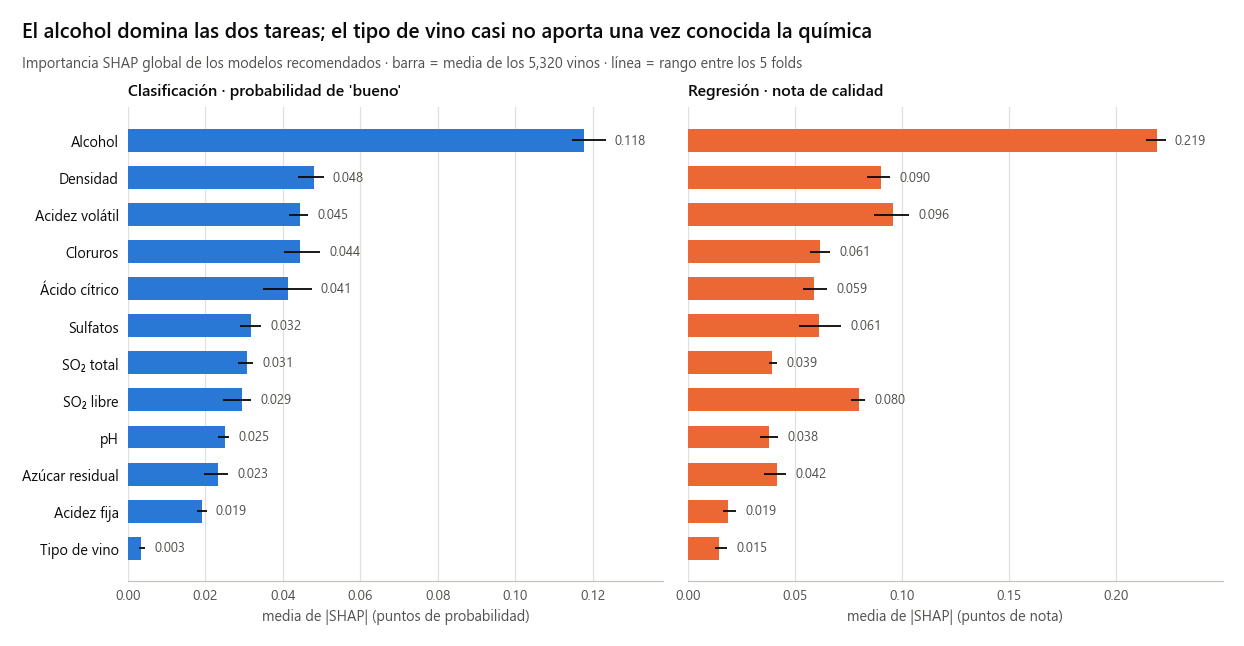

,variable,nombre,clf_media_abs_shap,clf_rango,clf_rango_min_fold,clf_rango_max_fold,clf_cv_entre_folds,reg_media_abs_shap,reg_rango,reg_rango_min_fold,reg_rango_max_fold,reg_cv_entre_folds,xgb_media_abs_shap,xgb_rango
0,alcohol,Alcohol,0.118,1,1,1,0.029,0.219,1,1,1,0.020,0.919,1
1,density,Densidad,0.048,2,2,5,0.050,0.090,3,2,3,0.048,0.379,3
2,volatile acidity,Acidez volátil,0.045,3,3,4,0.041,0.096,2,2,3,0.071,0.388,2
3,chlorides,Cloruros,0.044,4,3,4,0.085,0.061,5,5,6,0.072,0.324,4
4,citric acid,Ácido cítrico,0.041,5,2,5,0.118,0.059,7,5,7,0.076,0.284,7
5,sulphates,Sulfatos,0.032,6,6,8,0.078,0.061,6,5,7,0.122,0.310,5
6,total sulfur dioxide,SO₂ total,0.031,7,6,8,0.054,0.039,9,8,10,0.036,0.304,6
7,free sulfur dioxide,SO₂ libre,0.029,8,7,9,0.096,0.080,4,4,4,0.034,0.261,9
8,pH,pH,0.025,9,9,10,0.048,0.038,10,8,10,0.096,0.280,8
9,residual sugar,Azúcar residual,0.023,10,8,11,0.133,0.042,8,8,10,0.097,0.229,10


Correlación de Spearman entre rankings: clasificación vs regresión 0.89; Random Forest vs XGBoost (clasificación) 0.97


In [3]:
imp_clf, imp_reg, imp_xgb = importancia_shap(shap_clf), importancia_shap(shap_reg), importancia_shap(shap_xgb)
orden = imp_clf["variable"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(11, 5.0), layout="constrained", sharey=True)
for ax, valores, imp, color, titulo, unidad in [
    (axes[0], shap_clf, imp_clf, AZUL, "Clasificación · probabilidad de 'bueno'", "media de |SHAP| (puntos de probabilidad)"),
    (axes[1], shap_reg, imp_reg, NARANJA, "Regresión · nota de calidad", "media de |SHAP| (puntos de nota)"),
]:
    por_fold = valores.groupby("fold")[VARIABLES].apply(lambda g: g.abs().mean())
    imp = imp.set_index("variable").loc[orden]
    y = np.arange(len(orden))[::-1]
    ax.barh(y, imp["media_abs_shap"], height=0.62, color=color, zorder=2)
    ax.hlines(y, por_fold[orden].min(), por_fold[orden].max(), color=TINTA, lw=1.2, zorder=3)
    for yi, (variable, fila) in zip(y, imp.iterrows()):
        ax.text(por_fold[variable].max() + imp["media_abs_shap"].max() * 0.02, yi, f"{fila['media_abs_shap']:.3f}",
                va="center", fontsize=8.6, color=TINTA_2)
    ax.set_yticks(y, labels=[NOMBRE_VARIABLE[v] for v in orden])
    ax.tick_params(axis="y", labelcolor=TINTA)
    ax.set(xlabel=unidad, title=titulo)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.margins(x=0.12)
encabezado(fig, "El alcohol domina las dos tareas; el tipo de vino casi no aporta una vez conocida la química",
           "Importancia SHAP global de los modelos recomendados · barra = media de los 5,320 vinos · línea = rango entre los 5 folds")
guardar(fig, "fig22_shap_importancia_global")
plt.show()

tabla21 = (imp_clf.rename(columns=lambda c: c if c == "variable" else f"clf_{c}")
           .merge(imp_reg.rename(columns=lambda c: c if c == "variable" else f"reg_{c}"), on="variable")
           .merge(imp_xgb[["variable", "media_abs_shap", "rango"]].rename(columns={"media_abs_shap": "xgb_media_abs_shap",
                                                                               "rango": "xgb_rango"}), on="variable"))
tabla21.insert(1, "nombre", tabla21["variable"].map(NOMBRE_VARIABLE))
guardar_tabla(tabla21.round(5), "tabla21_importancia_shap")
display(tabla21.round(3))
rho_tareas = stats.spearmanr(tabla21["clf_media_abs_shap"], tabla21["reg_media_abs_shap"]).statistic
rho_familias = stats.spearmanr(tabla21["clf_media_abs_shap"], tabla21["xgb_media_abs_shap"]).statistic
print(f"Correlación de Spearman entre rankings: clasificación vs regresión {rho_tareas:.2f}; "
      f"Random Forest vs XGBoost (clasificación) {rho_familias:.2f}")

> **Resultado:** el **alcohol** es por lejos la variable más importante en las dos tareas: en promedio mueve la probabilidad de "bueno" en 0.12 y la nota en 0.22 puntos, más del doble que la segunda. Le siguen la **densidad**, la **acidez volátil** y los **cloruros**, y en regresión también el **SO₂ libre**. El **tipo de vino** queda último: una vez conocida la química, saber si es tinto o blanco casi no agrega información. Los rankings son estables: el alcohol es primero en los 5 folds de las dos tareas y ninguna variable se mueve más de tres puestos entre folds. Además, el orden coincide entre tareas (correlación de Spearman 0.89) y entre familias de modelos (0.97 con XGBoost + `class_weight`, que pone las mismas variables arriba), así que no es un artefacto de un modelo en particular. Esto concuerda con el EDA, donde el alcohol era la variable más correlacionada con la calidad y la densidad la segunda (con signo opuesto, porque el alcohol baja la densidad del vino).

## 2. Dirección del efecto

La importancia global no dice si una variable sube o baja la predicción. En el gráfico de enjambre cada punto es un vino: su posición horizontal es el aporte SHAP de esa variable y su color el valor de la variable (rojo = bajo, azul = alto, según su percentil).

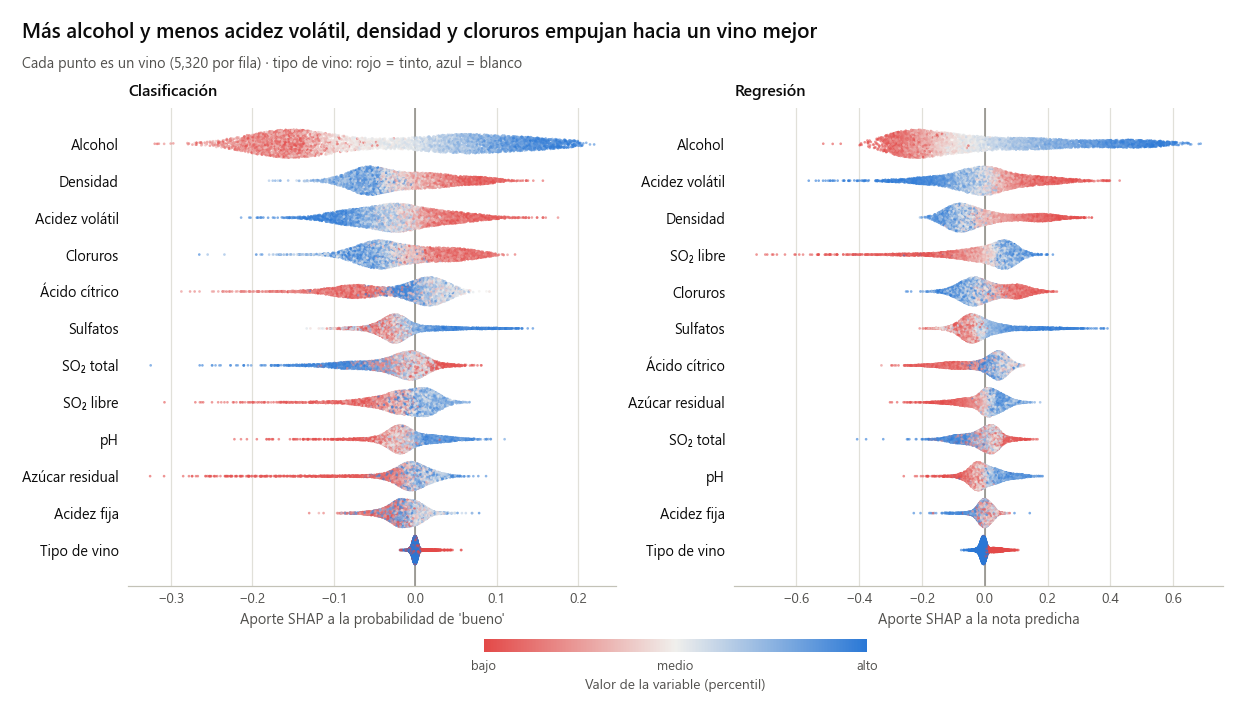

In [4]:
def enjambre(ax, valores, X, orden, rng):
    for fila, variable in enumerate(orden):
        y = len(orden) - 1 - fila
        v = valores[variable].to_numpy()
        x_var = (X["tipo_vino"] == "white").astype(float).to_numpy() if variable == "tipo_vino" else X[variable].to_numpy()
        percentil = x_var if variable == "tipo_vino" else stats.rankdata(x_var) / len(x_var)
        densidad = stats.gaussian_kde(v[::10] + rng.normal(0, 1e-6, len(v[::10])))(v)
        altura = 0.38 * densidad / densidad.max()
        orden_dibujo = rng.permutation(len(v))
        ax.scatter(v[orden_dibujo], y + rng.uniform(-1, 1, len(v)) * altura[orden_dibujo], c=percentil[orden_dibujo],
                   cmap=CMAP_DIVERGENTE, vmin=0, vmax=1, s=3, alpha=0.6, lw=0, rasterized=True, zorder=2)
    ax.axvline(0, color=TINTA_3, lw=1, zorder=1)
    ax.set_yticks(range(len(orden))[::-1], labels=[NOMBRE_VARIABLE[v] for v in orden])
    ax.tick_params(axis="y", labelcolor=TINTA)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)


rng = np.random.default_rng(config.RANDOM_STATE)
X_ordenado = X.reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), layout="constrained")
enjambre(axes[0], shap_clf, X_ordenado.iloc[shap_clf["idx"]].reset_index(drop=True), orden, rng)
enjambre(axes[1], shap_reg, X_ordenado.iloc[shap_reg["idx"]].reset_index(drop=True), imp_reg["variable"].tolist(), rng)
axes[0].set(title="Clasificación", xlabel="Aporte SHAP a la probabilidad de 'bueno'")
axes[1].set(title="Regresión", xlabel="Aporte SHAP a la nota predicha")
barra = fig.colorbar(plt.cm.ScalarMappable(norm=mcolors.Normalize(0, 1), cmap=CMAP_DIVERGENTE), ax=axes,
                     orientation="horizontal", location="bottom", shrink=0.35, aspect=30, pad=0.02, ticks=[0, 0.5, 1])
barra.ax.set_xticklabels(["bajo", "medio", "alto"])
barra.outline.set_visible(False)
barra.ax.tick_params(labelsize=8.5, colors=TINTA_2, length=0)
barra.set_label("Valor de la variable (percentil)", fontsize=9, color=TINTA_2)
encabezado(fig, "Más alcohol y menos acidez volátil, densidad y cloruros empujan hacia un vino mejor",
           "Cada punto es un vino (5,320 por fila) · tipo de vino: rojo = tinto, azul = blanco")
guardar(fig, "fig23_shap_enjambre")
plt.show()

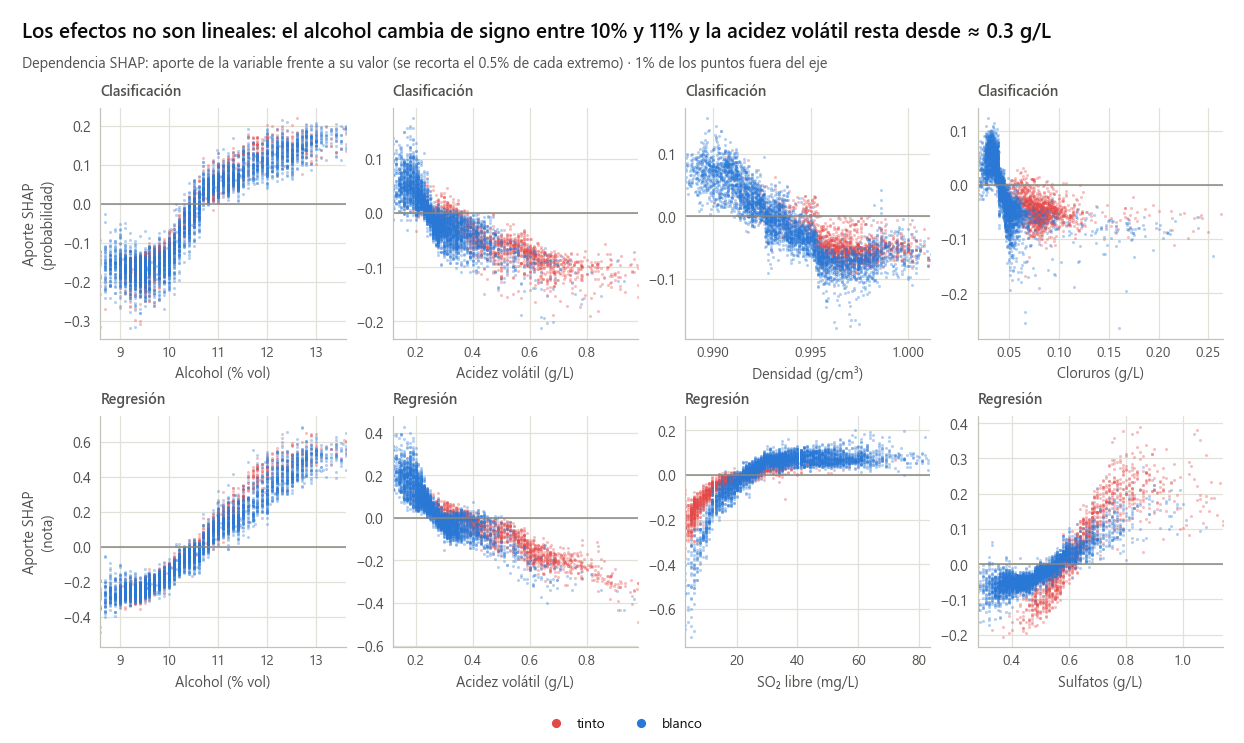

In [5]:
DEPENDENCIAS = [("clasificacion", "alcohol"), ("clasificacion", "volatile acidity"), ("clasificacion", "density"),
                ("clasificacion", "chlorides"), ("regresion", "alcohol"), ("regresion", "volatile acidity"),
                ("regresion", "free sulfur dioxide"), ("regresion", "sulphates")]
COLOR_TIPO = {"red": ROJO, "white": AZUL}
fig, axes = plt.subplots(2, 4, figsize=(11, 5.9), layout="constrained")
for ax, (tarea, variable) in zip(axes.flat, DEPENDENCIAS):
    valores = shap_clf if tarea == "clasificacion" else shap_reg
    x = X_ordenado.iloc[valores["idx"]]
    for tipo, color in COLOR_TIPO.items():
        m = (x["tipo_vino"] == tipo).to_numpy()
        ax.scatter(x[variable].to_numpy()[m], valores[variable].to_numpy()[m], s=4, color=color, alpha=0.35, lw=0,
                   rasterized=True)
    limite = np.quantile(x[variable], [0.005, 0.995])
    ax.set_xlim(*limite)
    ax.axhline(0, color=TINTA_3, lw=1)
    unidad = f" ({UNIDADES[variable]})" if UNIDADES[variable] else ""
    ax.set_xlabel(f"{NOMBRE_VARIABLE[variable]}{unidad}")
    ax.set_title("Clasificación" if tarea == "clasificacion" else "Regresión", fontsize=9.5, color=TINTA_2)
    ax.grid(True)
    ax.set_axisbelow(True)
axes[0, 0].set_ylabel("Aporte SHAP\n(probabilidad)")
axes[1, 0].set_ylabel("Aporte SHAP\n(nota)")
fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=5, color=ROJO, label="tinto"),
                    Line2D([], [], ls="", marker="o", ms=5, color=AZUL, label="blanco")],
           loc="outside lower center", ncols=2)
encabezado(fig, "Los efectos no son lineales: el alcohol cambia de signo entre 10% y 11% y la acidez volátil resta desde ≈ 0.3 g/L",
           "Dependencia SHAP: aporte de la variable frente a su valor (se recorta el 0.5% de cada extremo) · 1% de los puntos fuera del eje")
guardar(fig, "fig24_shap_dependencias")
plt.show()

> **Resultado:** las direcciones coinciden con lo que se sabe del vino y con el EDA. **Más alcohol** siempre aumenta la probabilidad de "bueno" y la nota, pero no de forma lineal: bajo 10% el aporte es negativo y casi constante, entre 10% y 11% sube rápido y cambia de signo, y por encima sigue subiendo más despacio. La **acidez volátil** (ácido acético, el olor a vinagre) resta desde ≈ 0.3 g/L; con la misma acidez, los tintos se penalizan algo menos que los blancos, que naturalmente tienen menos (medianas de 0.52 y 0.26 g/L). Menos **densidad** y menos **cloruros** suman (la densidad baja va de la mano con más alcohol y menos azúcar; los cloruros restan sobre ≈ 0.05 g/L). En regresión, el **SO₂ libre** muestra un umbral claro: por debajo de ≈ 20 mg/L el vino queda poco protegido frente a la oxidación y la nota baja, y sobre ≈ 30 mg/L el efecto se aplana. Los **sulfatos** suman desde ≈ 0.6 g/L, sobre todo en los tintos. Estas formas (umbrales, saturación, interacción con el tipo de vino) explican por qué los modelos de árboles superan a los lineales.

## 3. Explicaciones locales: LIME frente a SHAP

Para un vino en particular interesa saber qué lo llevó a su predicción. Se eligen tres casos de la clasificación: un vino bueno que el modelo reconoce con seguridad (verdadero positivo), uno bueno que se le escapa (falso negativo) y uno que no es bueno pero el modelo marca como tal (falso positivo). Para cada uno se comparan las 6 variables con más peso según LIME y según SHAP. LIME usa 5,000 vinos perturbados y discretiza cada variable en cuartiles del entrenamiento, por eso habla de intervalos ("alcohol > 11.4") en vez de valores.

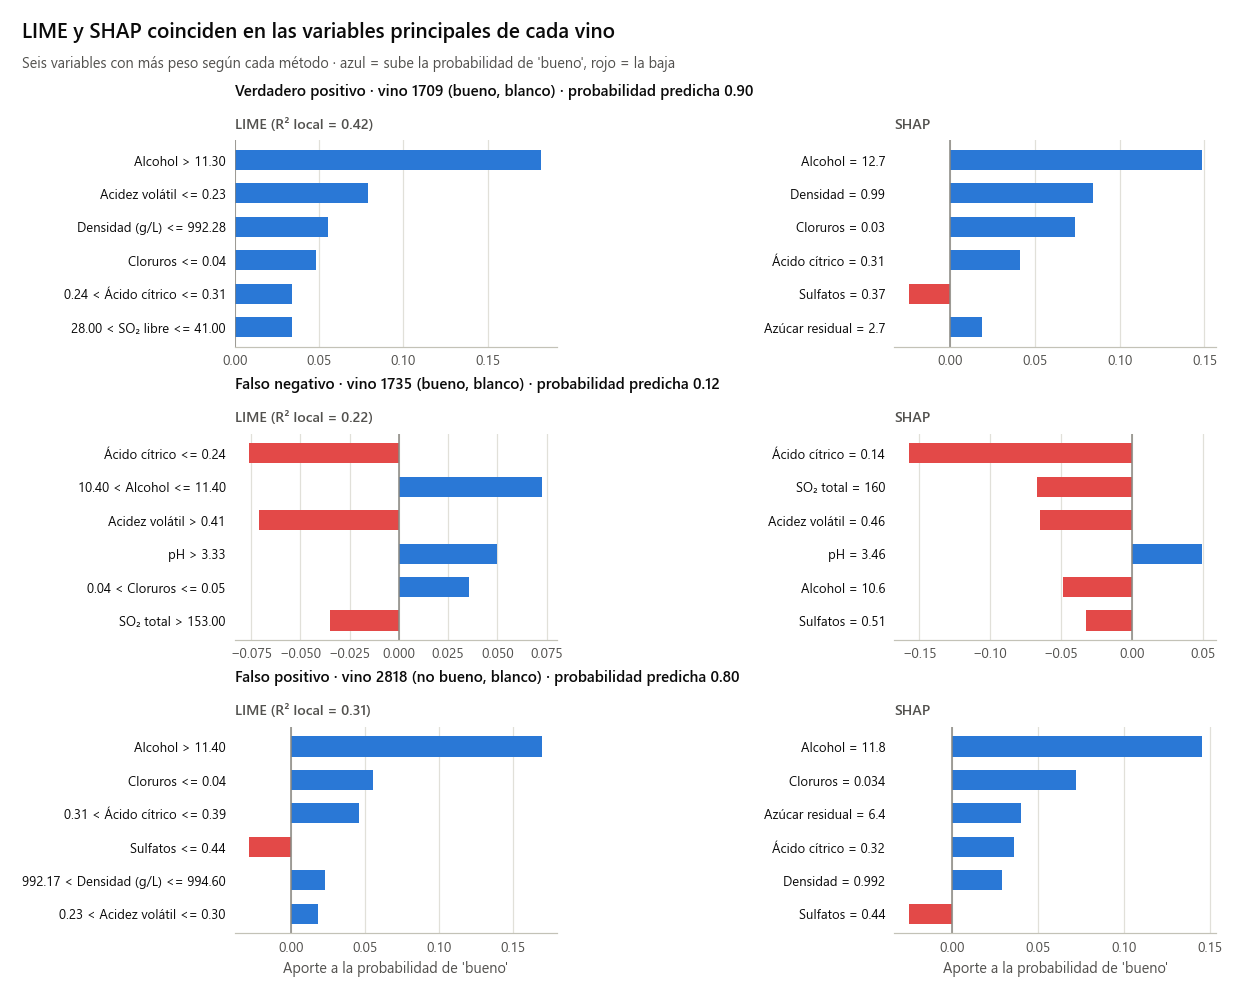

In [6]:
NOMBRES_LIME = [NOMBRE_VARIABLE[v] + (" (g/L)" if v == "density" else "") for v in VARIABLES]
combo_clf = EXPLICADOS["clasificacion"][0]
filas_clf = filas_combinacion(log_clf, *combo_clf)
oof_rec = oof_clf[(oof_clf["modelo"] == combo_clf[0]) & (oof_clf["balanceo"] == combo_clf[1])
                  & (oof_clf["optimizador"] == combo_clf[2])].set_index("idx").sort_index()


def caso(condicion, objetivo):
    candidatos = oof_rec[condicion]
    return int((candidatos["score"] - objetivo).abs().idxmin())


CASOS = {"Verdadero positivo": caso((oof_rec["y_true"] == 1), 0.90),
         "Falso negativo": caso((oof_rec["y_true"] == 1), 0.12),
         "Falso positivo": caso((oof_rec["y_true"] == 0), 0.80)}

ruta_locales = RUTA_INTERPRETABILIDAD / "lime_casos.csv"
modelos_fold = {}


def modelo_del_fold(fold):
    if fold not in modelos_fold:
        pipe, tr, te = ajustar_fold("clasificacion", filas_clf.iloc[fold], X, y_clf)
        modelos_fold[fold] = (pipe, explicador_lime("clasificacion", X.iloc[tr], nombres=NOMBRES_LIME))
    return modelos_fold[fold]


if ruta_locales.exists():
    lime_casos = pd.read_csv(ruta_locales)
else:
    partes = []
    for nombre_caso, idx in CASOS.items():
        pipe, explicador = modelo_del_fold(int(oof_rec.loc[idx, "fold"]))
        e = explicar_lime(explicador, pipe, "clasificacion", X.iloc[[idx]])
        partes.append(e.assign(caso=nombre_caso, idx=idx))
    lime_casos = pd.concat(partes, ignore_index=True)
    lime_casos.to_csv(ruta_locales, index=False)

shap_por_idx = shap_clf.set_index("idx")
fig, axes = plt.subplots(3, 2, figsize=(11, 8.2), layout="constrained")
for fila_ax, (nombre_caso, idx) in zip(axes, CASOS.items()):
    vino = oof_rec.loc[idx]
    e = lime_casos[lime_casos["caso"] == nombre_caso].head(6).iloc[::-1]
    s = shap_por_idx.loc[idx, VARIABLES].astype(float)
    s = s.reindex(s.abs().sort_values().index[-6:])
    for ax, etiquetas, pesos, titulo in [
        (fila_ax[0], e["condicion"].tolist(), e["peso"].to_numpy(), f"LIME (R² local = {e['r2_local'].iloc[0]:.2f})"),
        (fila_ax[1], [f"{NOMBRE_VARIABLE[v]} = {X.loc[idx, v]:.3g}" if v != "tipo_vino" else
                      f"Tipo de vino = {'blanco' if X.loc[idx, v] == 'white' else 'tinto'}" for v in s.index],
         s.to_numpy(), "SHAP"),
    ]:
        y = np.arange(len(pesos))
        ax.barh(y, pesos, height=0.6, color=[AZUL if p > 0 else ROJO for p in pesos], zorder=2)
        ax.set_yticks(y, labels=etiquetas, fontsize=8.6)
        ax.tick_params(axis="y", labelcolor=TINTA)
        ax.axvline(0, color=TINTA_3, lw=1)
        ax.grid(axis="x")
        ax.set_axisbelow(True)
        ax.spines["left"].set_visible(False)
        ax.set_title(titulo, fontsize=9.3, color=TINTA_2)
    fila_ax[0].text(0, 1.22, f"{nombre_caso} · vino {idx} ({'bueno' if vino['y_true'] == 1 else 'no bueno'}, "
                             f"{'tinto' if X.loc[idx, 'tipo_vino'] == 'red' else 'blanco'}) · probabilidad predicha {vino['score']:.2f}",
                    transform=fila_ax[0].transAxes, fontsize=10, fontweight="semibold", color=TINTA)
for ax in axes[-1]:
    ax.set_xlabel("Aporte a la probabilidad de 'bueno'")
encabezado(fig, "LIME y SHAP coinciden en las variables principales de cada vino",
           "Seis variables con más peso según cada método · azul = sube la probabilidad de 'bueno', rojo = la baja")
guardar(fig, "fig25_lime_vs_shap_casos")
plt.show()

> **Resultado:** en los tres casos las dos técnicas coinciden en la variable principal y en la mayoría de las seis primeras. El verdadero positivo (blanco, nota 7) tiene 12.7% de alcohol, baja densidad y pocos cloruros. El falso negativo es un blanco de nota 7 con perfil químico de vino común: alcohol medio (10.6%), poco ácido cítrico, mucho SO₂ total y una acidez volátil de 0.46 g/L, alta para un blanco; son los casos que la química disponible no permite rescatar. El falso positivo es un blanco de nota 6 con el perfil de un vino bueno (11.8% de alcohol, pocos cloruros, baja densidad). Las diferencias están en el detalle: en el falso negativo LIME le da al alcohol un peso positivo y SHAP uno negativo, porque LIME compara el intervalo 10.4–11.4% con los demás intervalos (incluido el de menos de 9.5%), mientras que SHAP compara 10.6% con la predicción promedio. Además, el R² local de LIME es bajo (0.22 a 0.42): el modelo lineal alrededor del vino solo explica una parte del comportamiento del bosque, mientras que SHAP reparte exactamente la predicción.

## 4. Estabilidad de LIME

LIME muestrea vinos perturbados al azar, así que dos corridas sobre el mismo vino pueden dar pesos distintos. Se repite la explicación del verdadero positivo 30 veces con semillas distintas, con 5,000 y con 1,000 muestras. SHAP (TreeExplainer) es determinista: da siempre el mismo resultado.

,muestras,top1_mas_frecuente,% corridas con el mismo top-1,% corridas con el mismo top-3,segundos_por_explicacion
0,1000,alcohol,100.0,80.00,0.08
1,5000,alcohol,100.0,96.67,0.21


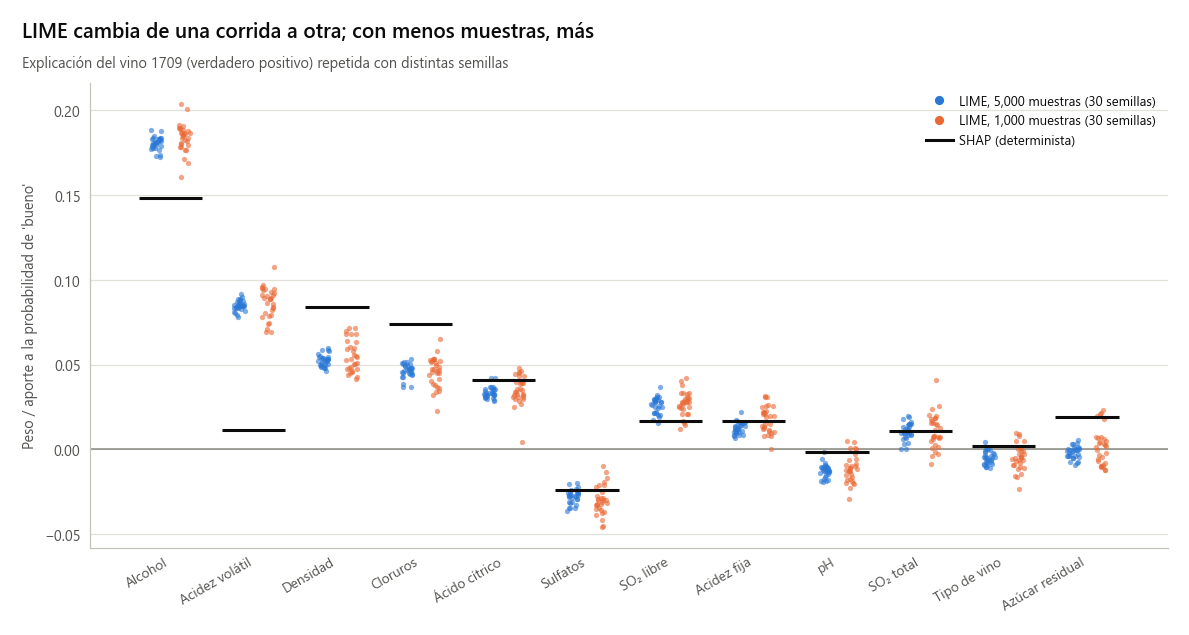

In [7]:
ruta_estabilidad = RUTA_INTERPRETABILIDAD / "lime_estabilidad.csv"
idx_estable = CASOS["Verdadero positivo"]
if ruta_estabilidad.exists():
    estabilidad = pd.read_csv(ruta_estabilidad)
else:
    fold = int(oof_rec.loc[idx_estable, "fold"])
    pipe, _ = modelo_del_fold(fold)
    tr, _ = particiones_externas("clasificacion", X, y_clf)[fold]
    partes = []
    for muestras in [5000, 1000]:
        for semilla in range(30):
            explicador = explicador_lime("clasificacion", X.iloc[tr], semilla=semilla, nombres=NOMBRES_LIME)
            t0 = time.perf_counter()
            e = explicar_lime(explicador, pipe, "clasificacion", X.iloc[[idx_estable]], num_samples=muestras)
            partes.append(e.assign(muestras=muestras, semilla=semilla, segundos=time.perf_counter() - t0))
    estabilidad = pd.concat(partes, ignore_index=True)
    estabilidad.to_csv(ruta_estabilidad, index=False)

resumen_estabilidad = (estabilidad.groupby(["muestras", "variable"])["peso"].agg(["mean", "std"])
                       .assign(cv=lambda t: t["std"] / t["mean"].abs()).reset_index())
top = estabilidad.assign(rango=estabilidad.groupby(["muestras", "semilla"])["peso"]
                         .transform(lambda p: p.abs().rank(ascending=False, method="first")))
coincidencia = []
for muestras, g in top.groupby("muestras"):
    top1 = g[g["rango"] == 1].groupby("semilla")["variable"].first()
    top3 = g[g["rango"] <= 3].groupby("semilla")["variable"].apply(frozenset)
    coincidencia.append({"muestras": muestras, "top1_mas_frecuente": top1.mode().iloc[0],
                         "% corridas con el mismo top-1": 100 * (top1 == top1.mode().iloc[0]).mean(),
                         "% corridas con el mismo top-3": 100 * (top3 == top3.mode().iloc[0]).mean(),
                         "segundos_por_explicacion": g.groupby("semilla")["segundos"].first().mean()})
coincidencia = pd.DataFrame(coincidencia)
display(coincidencia.round(2))

orden_vino = (estabilidad[estabilidad["muestras"] == 5000].groupby("variable")["peso"].mean().abs()
              .sort_values(ascending=False).index.tolist())
fig, ax = plt.subplots(figsize=(10.5, 4.9), layout="constrained")
shap_vino = shap_por_idx.loc[idx_estable, VARIABLES].astype(float)
for i, variable in enumerate(orden_vino):
    for desplazamiento, muestras, color in [(-0.17, 5000, AZUL), (0.17, 1000, NARANJA)]:
        p = estabilidad[(estabilidad["variable"] == variable) & (estabilidad["muestras"] == muestras)]["peso"]
        ax.scatter(i + desplazamiento + rng.uniform(-0.07, 0.07, len(p)), p, s=12, color=color, alpha=0.6, lw=0, zorder=3)
    ax.plot([i - 0.38, i + 0.38], [shap_vino[variable]] * 2, color=TINTA, lw=2, zorder=4, solid_capstyle="butt")
ax.axhline(0, color=TINTA_3, lw=1)
ax.set_xticks(range(len(orden_vino)), labels=[NOMBRE_VARIABLE[v] for v in orden_vino], rotation=30, ha="right")
ax.set_ylabel("Peso / aporte a la probabilidad de 'bueno'")
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=5, color=AZUL, label="LIME, 5,000 muestras (30 semillas)"),
                   Line2D([], [], ls="", marker="o", ms=5, color=NARANJA, label="LIME, 1,000 muestras (30 semillas)"),
                   Line2D([], [], color=TINTA, lw=2, label="SHAP (determinista)")], loc="upper right", fontsize=8.6)
encabezado(fig, "LIME cambia de una corrida a otra; con menos muestras, más",
           f"Explicación del vino {idx_estable} (verdadero positivo) repetida con distintas semillas")
guardar(fig, "fig26_lime_estabilidad")
plt.show()

> **Resultado:** el orden de las variables principales se mantiene (el alcohol es la primera en todas las corridas), pero los pesos de LIME varían de una semilla a otra, y bastante más con 1,000 muestras que con 5,000; las variables de peso intermedio cambian de puesto. Esto es una limitación conocida de LIME: dos personas que explican el mismo vino pueden obtener tablas distintas. Más llamativa que la variación entre semillas es la diferencia sistemática con SHAP en algunas variables: para este vino LIME le da a la acidez volátil un peso de ≈ 0.085 y SHAP un aporte de apenas 0.011. Notar también que los pesos de LIME y los aportes SHAP no son la misma magnitud (LIME mide el efecto de estar en un intervalo frente a no estarlo en un modelo lineal local; SHAP reparte la predicción), por eso se comparan rankings y signos, no valores exactos.

## 5. Coincidencia global entre LIME y SHAP

Para ver si la coincidencia de los casos individuales se mantiene en general, se explican con LIME 200 vinos elegidos al azar (estratificados por clase) y se compara, vino por vino, el orden de las variables según |peso LIME| y según |SHAP| (correlación de Spearman), además del signo de las 5 variables principales.

,valor
vinos explicados,200
Spearman por vino (mediana),0.646853
Spearman por vino (percentil 10–90),0.31 – 0.83
% vinos con la misma variable principal,59.5
% de signos que coinciden (top-5 SHAP),90.9
R² local de LIME (mediana),0.2517
Spearman del ranking global,0.916084
segundos por vino: LIME,0.204768
segundos por vino: SHAP (CPU),0.078377


,variable,nombre,media_abs_lime,media_abs_shap,rango_lime,rango_shap
0,alcohol,Alcohol,0.1102,0.1213,1,1
1,density,Densidad,0.0361,0.0468,4,2
2,chlorides,Cloruros,0.0343,0.0448,5,3
3,volatile acidity,Acidez volátil,0.0427,0.0413,2,4
4,citric acid,Ácido cítrico,0.0392,0.0396,3,5
5,sulphates,Sulfatos,0.0269,0.0304,7,6
6,free sulfur dioxide,SO₂ libre,0.0302,0.0303,6,7
7,total sulfur dioxide,SO₂ total,0.0167,0.0299,9,8
8,residual sugar,Azúcar residual,0.0144,0.0271,10,9
9,pH,pH,0.0241,0.0251,8,10


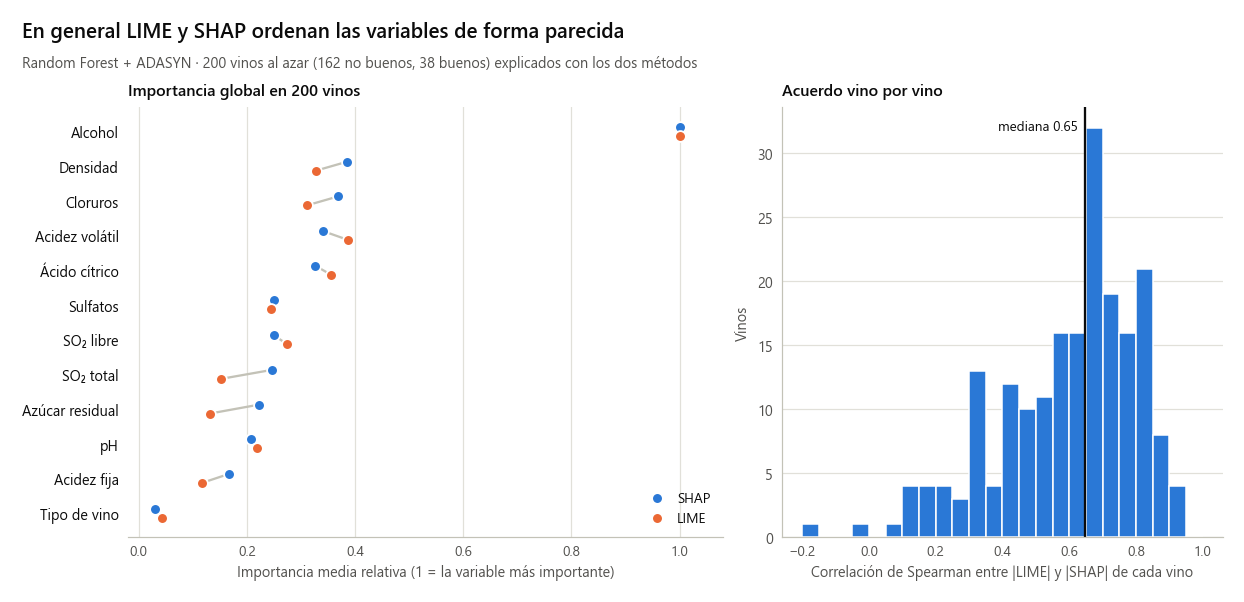

In [8]:
ruta_global = RUTA_INTERPRETABILIDAD / "lime_global.csv"
rng_muestra = np.random.default_rng(config.RANDOM_STATE)
muestra = np.concatenate([rng_muestra.choice(oof_rec.index[oof_rec["y_true"] == c], n, replace=False)
                          for c, n in [(0, 162), (1, 38)]])
if ruta_global.exists():
    lime_global = pd.read_csv(ruta_global)
else:
    partes = []
    t0 = time.perf_counter()
    for idx in muestra:
        pipe, explicador = modelo_del_fold(int(oof_rec.loc[idx, "fold"]))
        partes.append(explicar_lime(explicador, pipe, "clasificacion", X.iloc[[idx]]).assign(idx=idx))
    lime_global = pd.concat(partes, ignore_index=True)
    lime_global["segundos_por_vino"] = (time.perf_counter() - t0) / len(muestra)
    lime_global.to_csv(ruta_global, index=False)

filas = []
for idx, g in lime_global.groupby("idx"):
    lime_vino = g.set_index("variable")["peso"].reindex(VARIABLES)
    shap_v = shap_por_idx.loc[idx, VARIABLES].astype(float)
    principales = shap_v.abs().sort_values(ascending=False).index[:5]
    filas.append({"idx": idx, "spearman": stats.spearmanr(lime_vino.abs(), shap_v.abs()).statistic,
                  "mismo_top1": lime_vino.abs().idxmax() == shap_v.abs().idxmax(),
                  "signo_coincide_top5": (np.sign(lime_vino[principales]) == np.sign(shap_v[principales])).mean(),
                  "r2_local": g["r2_local"].iloc[0]})
acuerdo = pd.DataFrame(filas)
global_lime = lime_global.groupby("variable")["peso"].apply(lambda p: p.abs().mean()).reindex(VARIABLES)
global_shap = shap_clf[shap_clf["idx"].isin(muestra)][VARIABLES].abs().mean()
tabla22 = pd.DataFrame({"variable": VARIABLES, "nombre": [NOMBRE_VARIABLE[v] for v in VARIABLES],
                        "media_abs_lime": global_lime.to_numpy(), "media_abs_shap": global_shap.to_numpy()})
tabla22["rango_lime"] = tabla22["media_abs_lime"].rank(ascending=False).astype(int)
tabla22["rango_shap"] = tabla22["media_abs_shap"].rank(ascending=False).astype(int)
tabla22 = tabla22.sort_values("rango_shap").reset_index(drop=True)
guardar_tabla(tabla22.round(5), "tabla22_lime_vs_shap_global")

resumen_acuerdo = pd.Series({
    "vinos explicados": len(acuerdo),
    "Spearman por vino (mediana)": acuerdo["spearman"].median(),
    "Spearman por vino (percentil 10–90)": f"{acuerdo['spearman'].quantile(0.1):.2f} – {acuerdo['spearman'].quantile(0.9):.2f}",
    "% vinos con la misma variable principal": 100 * acuerdo["mismo_top1"].mean(),
    "% de signos que coinciden (top-5 SHAP)": 100 * acuerdo["signo_coincide_top5"].mean(),
    "R² local de LIME (mediana)": acuerdo["r2_local"].median(),
    "Spearman del ranking global": stats.spearmanr(tabla22["media_abs_lime"], tabla22["media_abs_shap"]).statistic,
    "segundos por vino: LIME": lime_global["segundos_por_vino"].iloc[0],
    "segundos por vino: SHAP (CPU)": t_clf["segundos_shap"].sum() / len(shap_clf),
})
display(resumen_acuerdo.to_frame("valor"))
display(tabla22.round(4))

fig, (ax_g, ax_h) = plt.subplots(1, 2, figsize=(11, 4.6), width_ratios=[1.35, 1], layout="constrained")
y = np.arange(len(tabla22))[::-1]
escala_lime = tabla22["media_abs_lime"] / tabla22["media_abs_lime"].max()
escala_shap = tabla22["media_abs_shap"] / tabla22["media_abs_shap"].max()
for yi, a, b in zip(y, escala_shap, escala_lime):
    ax_g.plot([a, b], [yi + 0.13, yi - 0.13], color=EJE, lw=1.5, zorder=1)
ax_g.scatter(escala_shap, y + 0.13, s=50, color=AZUL, zorder=3, label="SHAP", edgecolor=FONDO, lw=1.2)
ax_g.scatter(escala_lime, y - 0.13, s=50, color=NARANJA, zorder=3, label="LIME", edgecolor=FONDO, lw=1.2)
ax_g.set_yticks(y, labels=tabla22["nombre"])
ax_g.tick_params(axis="y", labelcolor=TINTA)
ax_g.set(xlabel="Importancia media relativa (1 = la variable más importante)", xlim=(-0.02, 1.08),
         title="Importancia global en 200 vinos")
ax_g.grid(axis="x")
ax_g.set_axisbelow(True)
ax_g.spines["left"].set_visible(False)
ax_g.legend(loc="lower right")
ax_h.hist(acuerdo["spearman"], bins=np.linspace(-0.2, 1, 25), color=AZUL, edgecolor=FONDO, zorder=2)
ax_h.axvline(acuerdo["spearman"].median(), color=TINTA, lw=1.5)
ax_h.text(acuerdo["spearman"].median(), ax_h.get_ylim()[1] * 0.97, f"mediana {acuerdo['spearman'].median():.2f}  ",
          fontsize=8.8, color=TINTA, va="top", ha="right")
ax_h.set(xlabel="Correlación de Spearman entre |LIME| y |SHAP| de cada vino", ylabel="Vinos", title="Acuerdo vino por vino")
ax_h.grid(axis="y")
ax_h.set_axisbelow(True)
encabezado(fig, "En general LIME y SHAP ordenan las variables de forma parecida",
           "Random Forest + ADASYN · 200 vinos al azar (162 no buenos, 38 buenos) explicados con los dos métodos")
guardar(fig, "fig27_lime_vs_shap_global")
plt.show()

> **Resultado:** a nivel global los dos métodos ordenan las variables casi igual (correlación de Spearman 0.92 entre los rankings: el alcohol primero y el tipo de vino último en ambos; las mayores diferencias están en el SO₂ total y el azúcar residual, a los que LIME da menos peso). Vino por vino el acuerdo es moderado: la correlación mediana es 0.65 (percentil 10–90: 0.31 a 0.83), coinciden en la variable principal en el 60% de los vinos y en el signo del 91% de los aportes de las cinco variables principales según SHAP. El R² local mediano de LIME es 0.25. En costo, SHAP tardó 78 ms de CPU por vino y LIME 205 ms (5,000 muestras).

## 6. Conclusiones de la interpretabilidad

1. **El alcohol es el factor dominante** en las dos tareas (importancia SHAP más del doble que la segunda variable), seguido de la densidad, la acidez volátil y los cloruros; en regresión también el SO₂ libre y los sulfatos. El tipo de vino casi no aporta una vez conocida la química. Los rankings son estables entre folds, entre tareas y entre Random Forest y XGBoost.
2. **Las relaciones no son lineales**: hay umbrales (el alcohol cambia de signo entre 10% y 11%, la acidez volátil resta desde ≈ 0.3 g/L, el SO₂ libre bajo ≈ 20 mg/L) y diferencias entre tintos y blancos. Esto explica la ventaja de los ensambles de árboles sobre la regresión logística y Ridge/Lasso.
3. **Los errores tienen sentido químico**: el modelo falla con vinos buenos de perfil químico común (alcohol medio, acidez volátil alta) y con vinos de perfil "bueno" que recibieron un 6; son casos que la química disponible no alcanza a distinguir, coherente con el techo de AUC ≈ 0.86.
4. **SHAP y LIME coinciden en lo principal** (ranking global casi igual, Spearman 0.92; misma variable más importante en el 60% de los vinos y 91% de signos coherentes), pero **SHAP es preferible para estos modelos**: es exacto (la suma de aportes reproduce la predicción), determinista y, con TreeExplainer, más rápido que LIME (78 frente a 205 ms por vino). LIME depende de la semilla y del número de muestras y su modelo local tiene un R² bajo; sirve como contraste agnóstico al modelo, no como explicación definitiva.
5. **Precaución:** las explicaciones describen al modelo, no relaciones causales del vino. Además, las variables correlacionadas (alcohol, densidad y azúcar residual) se reparten el crédito entre ellas, así que la importancia de cada una por separado debe leerse junto con la de las otras.